In [22]:
import pandas as pd

In [23]:
models = [
    {
        "model_name":"ConvNext finetuned",
    },
    {
        "model_name":"ConvNext from scratch",
    },
    {
        "model_name":"ConvNext transfer from genus",
    },
    {
        "model_name":"ResNet50",
    },
    {
        "model_name":"ResNet50_finetuned",
    },
]

In [24]:
def load_validated_motifs(
    model_name,
    min_sequences=5
):
    """
    Load motif results from the matched random-region control
    and retain statistically validated motifs.
    """

    clean_name = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    path = (
        "results_motifs_control/"
        f"summary_{clean_name}.parquet"
    )

    df = pd.read_parquet(path)

    df_valid = df[
        (df["significant_fdr"] == True)
        & (df["mean_specific_drop"] > 0)
        & (df["n_sequences"] >= min_sequences)
    ].copy()

    df_valid["motif"] = (
        df_valid["motif"]
        .astype(str)
    )

    print(
        f"{model_name}: "
        f"{len(df_valid)} validated motifs "
        f"of {len(df)} total motifs."
    )

    return df_valid

In [25]:
models

[{'model_name': 'ConvNext finetuned'},
 {'model_name': 'ConvNext from scratch'},
 {'model_name': 'ConvNext transfer from genus'},
 {'model_name': 'ResNet50'},
 {'model_name': 'ResNet50_finetuned'}]

In [26]:
import re
import numpy as np
import pandas as pd
from tqdm import tqdm

def gerar_rscu_map_from_loader(loader, nucleotides_list, num_batches_sample=50):
    """
    Consome batches do test_loader, decodifica os tensores numéricos de volta
    para strings de nucleotídeos e calcula o RSCU global.
    
    Parâmetros:
    - loader: O seu objeto test_loader do PyTorch.
    - nucleotides_list: A sua lista ['A', 'C', 'G', 'T'].
    - num_batches_sample: Quantidade de batches para amostrar (50 batches com 4096 
                          de tamanho dão ~200k leituras, excelente para convergência).
    """
    print(f"🧬 Inicializando extração de Codon Usage a partir de {num_batches_sample} batches do DataLoader...")
    
    # Código genético padrão (64 códons e os seus respectivos aminoácidos)
    genetic_code = {
        'A': ['GCA', 'GCC', 'GCG', 'GCT'],
        'R': ['AGA', 'AGG', 'CGA', 'CGC', 'CGG', 'CGT'],
        'N': ['AAC', 'AAT'], 'D': ['GAC', 'GAT'], 'C': ['TGC', 'TGT'],
        'E': ['GAA', 'GAG'], 'Q': ['CAA', 'CAG'], 'G': ['GGA', 'GGC', 'GGG', 'GGT'],
        'H': ['CAC', 'CAT'], 'I': ['ATA', 'ATC', 'ATT'], 'L': ['CTA', 'CTC', 'CTG', 'CTT', 'TTA', 'TTG'],
        'K': ['AAA', 'AAG'], 'F': ['TTC', 'TTT'], 'P': ['CCA', 'CCC', 'CCG', 'CCT'],
        'S': ['AGC', 'AGT', 'TCA', 'TCC', 'TCG', 'TCT'], 'T': ['ACA', 'ACC', 'ACG', 'ACT'],
        'Y': ['TAC', 'TAT'], 'V': ['GTA', 'GTC', 'GTG', 'GTT'], 'W': ['TGG'], 'M': ['ATG'],
        'STOP': ['TAA', 'TAG', 'TGA']
    }
    
    # Inicializa o dicionário de contagem global de códons
    contagem_global = {codon: 0 for codons_aa in genetic_code.values() for codon in codons_aa}
    
    # Dicionário reverso para traduzir o ID numérico do tensor de volta para a letra (ex: 0->A, 1->C...)
    idx_to_nuc = {idx: nuc for idx, nuc in enumerate(nucleotides_list)}
    
    batch_count = 0
    
    # Desliga qualquer cálculo de gradiente por segurança e itera no loader
    for batch in tqdm(loader, total=num_batches_sample, desc="Processando Batches"):
        if batch_count >= num_batches_sample:
            break
            
        # Dependendo de como o seu ParquetCPUDataset packeia o lote,
        # ele pode vir como uma tupla (X, y) ou um dicionário. Ajuste se necessário:
        if isinstance(batch, (list, tuple)):
            X_batch = batch[0]
        elif isinstance(batch, dict):
            X_batch = batch[PADDED_COLUMN]
        else:
            X_batch = batch
            
        # Converte para array numpy para manipulação rápida de CPU
        if hasattr(X_batch, 'numpy'):
            X_numpy = X_batch.numpy()
        else:
            X_numpy = np.array(X_batch)
            
        # Se os dados vierem em One-Hot Encoding (Shape: BATCH, SEQ_LEN, 4), reduz com argmax
        if len(X_numpy.shape) == 3:
            X_numpy = np.argmax(X_numpy, axis=-1)
            
        # Varre cada leitura/fragmento contido no batch
        for leitura_ints in X_numpy:
            # Traduz o vetor de inteiros de volta para a string de DNA textualmente
            seq_str = "".join([idx_to_nuc.get(int(i), '') for i in leitura_ints])
            
            # Limpeza rápida: remove caracteres espúrios ou restos de padding inválidos
            seq_clean = re.sub(r'[^ACGT]', '', seq_str.upper())
            
            # Varre em Frame 0 quebrando em tripletos
            for i in range(0, len(seq_clean) - 2, 3):
                codon = seq_clean[i:i+3]
                if codon in contagem_global:
                    contagem_global[codon] += 1
                    
        batch_count += 1
        
    # 🧮 Aplicação da fórmula matemática do RSCU
    print("\n📊 Traduzindo contagens absolutas para o mapa de RSCU...")
    rscu_map = {}
    
    for aa, codons_sinonimos in genetic_code.items():
        m = len(codons_sinonimos)
        total_aa_ocorrencias = sum([contagem_global[codon] for codon in codons_sinonimos])
        
        for codon in codons_sinonimos:
            if total_aa_ocorrencias == 0:
                rscu_map[codon] = 1.0 # Uso neutro se o aminoácido nunca foi visto
            else:
                frequencia_observada = contagem_global[codon]
                # Fórmula padrão: RSCU = Ocorrências / (Total_AA / Qtd_Sinônimos)
                rscu_map[codon] = frequencia_observada / (total_aa_ocorrencias / m)
                
    print(f"✅ 'rscu_map' estruturado com sucesso a partir do test_loader!")
    return rscu_map

In [27]:
from torch.utils.data import DataLoader, IterableDataset
from utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec
import os

fs = fsspec.filesystem('file')
test_file_paths = fs.glob(os.path.join(f"./processed_kraken_species_splited_parquet/test", '*.parquet'))
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'
BATCH_SIZE = 4096
MAX_SEQUENCE_LENGTH = 512
test_dataset = ParquetCPUDataset(
    test_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset, num_workers=8, pin_memory=True, prefetch_factor=2, batch_size=None
)

In [28]:
# 1. Gera o mapa global consumindo 50 batches do seu Dataloader de teste
rscu_map_loader = gerar_rscu_map_from_loader(
    loader=test_loader, 
    nucleotides_list=NUCLEOTIDES, 
    num_batches_sample=50
)



🧬 Inicializando extração de Codon Usage a partir de 50 batches do DataLoader...


Processando Batches: 100%|██████████| 50/50 [00:12<00:00,  4.05it/s]


📊 Traduzindo contagens absolutas para o mapa de RSCU...
✅ 'rscu_map' estruturado com sucesso a partir do test_loader!


In [29]:
def calcular_rscu_medio_motivo(
    motif,
    rscu_map
):
    """
    Calculate mean RSCU across all overlapping
    triplets contained in a motif.
    """

    if (
        not isinstance(motif, str)
        or len(motif) < 3
    ):
        return np.nan

    motif = motif.upper().strip()

    codons = [
        motif[i:i+3]
        for i in range(len(motif) - 2)
    ]

    valid_rscu = [
        rscu_map[codon]
        for codon in codons
        if codon in rscu_map
    ]

    if not valid_rscu:
        return np.nan

    return np.mean(valid_rscu)

In [30]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

def plot_codon_signature_match(df_top_motifs, model_name, rscu_map, path_save):
    """
    Gera um Scatter Plot com linha de regressão para verificar se a abundância
    dos códons nos motifs de cada modelo replica a assinatura de RSCU global do test set.
    """
    plt.clf()
    plt.close('all')
    
    # 1. Contagem absoluta de todos os códons encontrados nos motifs deste modelo
    contagem_codons_motif = {codon: 0 for codon in rscu_map.keys()}
    
    col_motif = 'motif' if 'motif' in df_top_motifs.columns else ('kmer' if 'kmer' in df_top_motifs.columns else None)
    
    for row in df_top_motifs.itertuples():
        motif_str = str(getattr(row, col_motif)).upper().strip()
        if len(motif_str) >= 3 and not any(char in motif_str for char in ['N', 'X', '-', '_']):
            # Extrai os sub-códons deslizantes
            for i in range(len(motif_str) - 2):
                codon = motif_str[i:i+3]
                if codon in contagem_codons_motif:
                    contagem_codons_motif[codon] += 1
                    
    # 2. Monta o DataFrame consolidando as duas variáveis para os 64 códons
    records = []
    total_codons_extraidos = sum(contagem_codons_motif.values())
    
    if total_codons_extraidos == 0:
        print(f"⚠️ Sem códons válidos extraídos para o modelo {model_name}.")
        return pd.DataFrame(), 1.0
        
    for codon, count in contagem_codons_motif.items():
        records.append({
            'Codon': codon,
            'RSCU_Global': rscu_map[codon],
            'Frequencia_no_Motif_Pct': (count / total_codons_extraidos) * 100
        })
        
    df_signature = pd.DataFrame(records)
    
    # 3. Calcula as correlações para colocar no gráfico
    p_corr, p_val = pearsonr(df_signature['RSCU_Global'], df_signature['Frequencia_no_Motif_Pct'])
    s_corr, s_val = spearmanr(df_signature['RSCU_Global'], df_signature['Frequencia_no_Motif_Pct'])
    
    # 4. Renderização do Gráfico de Dispersão com Regressão Linear
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.set_theme(style="whitegrid")
    
    # Linha de tendência + pontos
    sns.regplot(
        data=df_signature, x='RSCU_Global', y='Frequencia_no_Motif_Pct',
        scatter_kws={'alpha': 0.7, 's': 50, 'color': '#1f77b4'},
        line_kws={'color': '#d62728', 'linewidth': 2}, ax=ax
    )
    
    # 🛠️ CORREÇÃO DAQUI: Acessando de forma segura sem caracteres especiais nos atributos
    top_codons = df_signature.sort_values(by='Frequencia_no_Motif_Pct', ascending=False).head(5)
    for row in top_codons.itertuples():
        # Usa o nome limpo 'Frequencia_no_Motif_Pct' que definimos no dicionário
        ax.text(row.RSCU_Global + 0.02, row.Frequencia_no_Motif_Pct + 0.05, row.Codon, 
                fontsize=9, weight='bold', alpha=0.8)
        
    # Adiciona linha vertical tracejada indicando o uso neutro do RSCU (1.0)
    ax.axvline(x=1.0, color='gray', linestyle='--', alpha=0.6)
    
    # Caixa de texto com os coeficientes de correlação
    texto_stats = (
        f"Alinhamento de Assinatura:\n"
        f"Pearson r: {p_corr:.4f} (p:{p_val:.2e})\n"
        f"Spearman ρ: {s_corr:.4f} (p:{s_val:.2e})"
    )
    ax.text(0.05, 0.95, texto_stats, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='lightgray'))
    
    ax.set_title(f'Global RSCU vs. Motif Codon Frequency\nModelo: {model_name.upper()}', fontweight='bold', fontsize=12, pad=12)
    ax.set_xlabel('RSCU Global of Test Set', fontweight='bold')
    ax.set_ylabel('Frequency of Occurrence in the Model Motifs (%)', fontweight='bold')
    
    plt.tight_layout()
    
    os.makedirs(os.path.dirname(path_save), exist_ok=True)
    plt.savefig(path_save, dpi=300, bbox_inches='tight')
    plt.show()
    plt.clf()
    plt.close(fig)
    plt.close('all')
    
    print(f"🎯 [{model_name}] Scatter plot de aderência salvo! Pearson r = {p_corr:.4f}")
    
    return df_signature, p_corr

In [31]:
print(rscu_map_loader)

{'GCA': 1.0659724664227868, 'GCC': 0.9848014233904194, 'GCG': 0.9103442484425107, 'GCT': 1.038881861744283, 'AGA': 1.2688734679972946, 'AGG': 1.0185761007221623, 'CGA': 0.995087471234304, 'CGC': 0.9251560955480786, 'CGG': 0.907457308464473, 'CGT': 0.8848495560336871, 'AAC': 0.9223094246470886, 'AAT': 1.0776905753529114, 'GAC': 0.8903553955576505, 'GAT': 1.1096446044423494, 'TGC': 0.9506209145460772, 'TGT': 1.0493790854539229, 'GAA': 1.1399857272586786, 'GAG': 0.8600142727413214, 'CAA': 1.0937835116260821, 'CAG': 0.9062164883739178, 'GGA': 1.0914937887471223, 'GGC': 0.9988052416031485, 'GGG': 0.8519372762490124, 'GGT': 1.0577636934007169, 'CAC': 0.8974596573701578, 'CAT': 1.1025403426298424, 'ATA': 0.9251435299419254, 'ATC': 0.9665921496466701, 'ATT': 1.1082643204114047, 'CTA': 0.6858032061696255, 'CTC': 0.9062934291138992, 'CTG': 1.022406976061383, 'CTT': 1.1507124821390122, 'TTA': 1.0049117716142417, 'TTG': 1.2298721349018378, 'AAA': 1.1158436827898073, 'AAG': 0.8841563172101928, 'TTC

carregando dados para convnext_finetuned
ConvNext finetuned: 34 validated motifs of 63 total motifs.


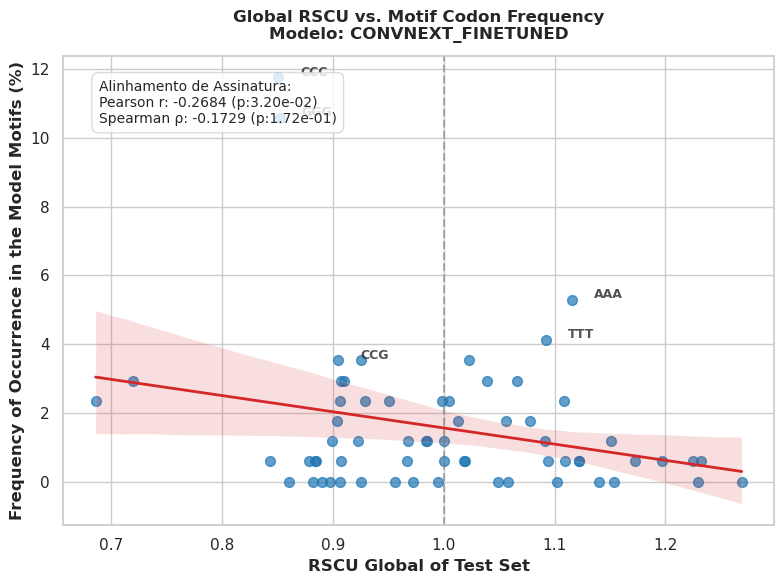

🎯 [convnext_finetuned] Scatter plot de aderência salvo! Pearson r = -0.2684
carregando dados para convnext_from_scratch
ConvNext from scratch: 30 validated motifs of 54 total motifs.


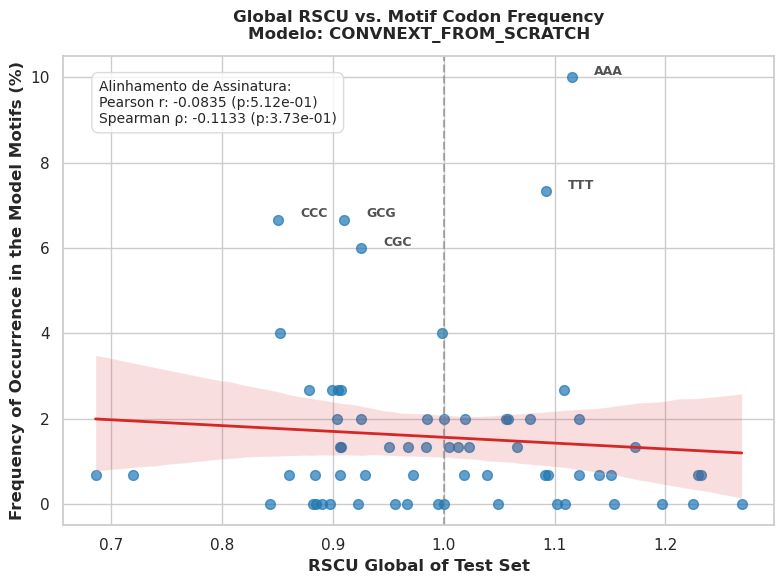

🎯 [convnext_from_scratch] Scatter plot de aderência salvo! Pearson r = -0.0835
carregando dados para convnext_transfer_from_genus
ConvNext transfer from genus: 40 validated motifs of 61 total motifs.


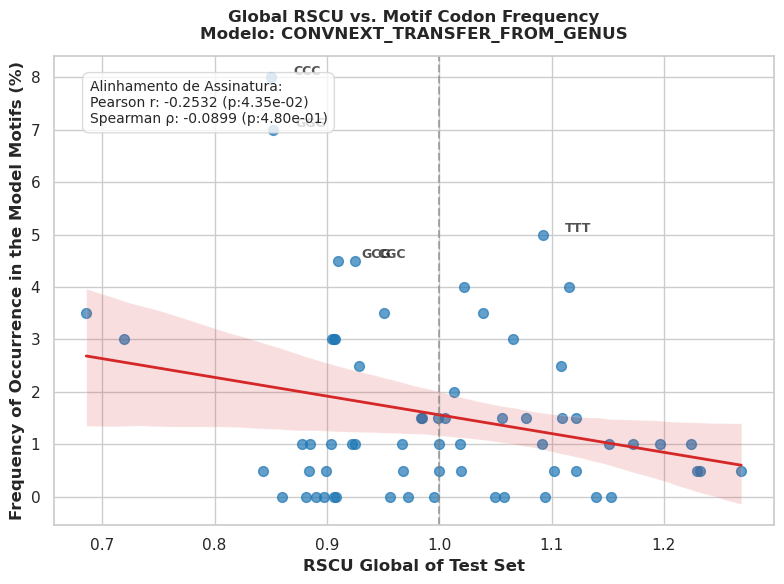

🎯 [convnext_transfer_from_genus] Scatter plot de aderência salvo! Pearson r = -0.2532
carregando dados para resnet50
ResNet50: 42 validated motifs of 64 total motifs.


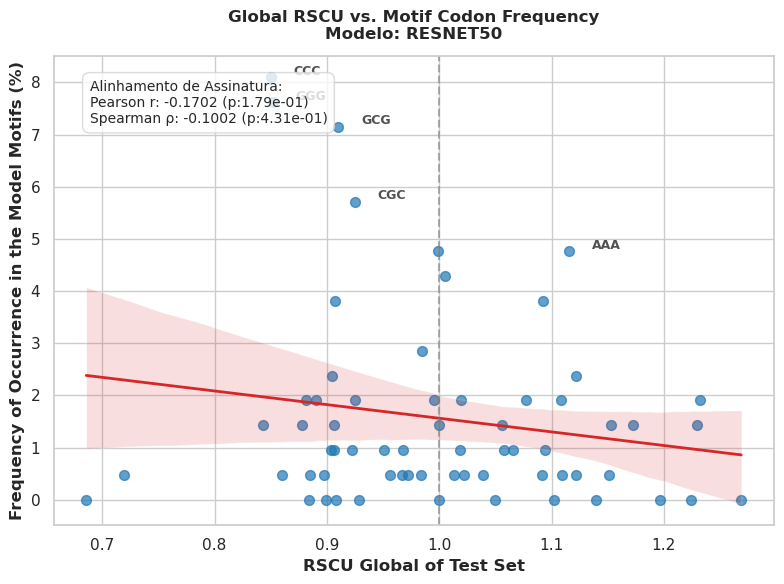

🎯 [resnet50] Scatter plot de aderência salvo! Pearson r = -0.1702
carregando dados para resnet50_finetuned
ResNet50_finetuned: 40 validated motifs of 62 total motifs.


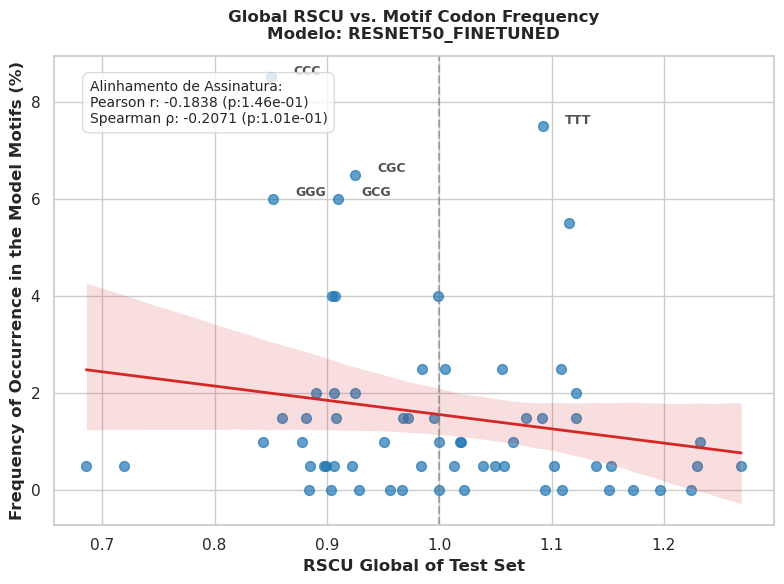

🎯 [resnet50_finetuned] Scatter plot de aderência salvo! Pearson r = -0.1838


In [32]:
for model in models:
    model_name = model['model_name'].lower().replace(" ","_")
    print(f"carregando dados para {model_name}")
    df_top_motifs = load_validated_motifs(
                        model["model_name"]
                    )
    # 2. Executa a análise estatística (Estratégia C) cruzando os dados com o seu DataFrame de motifs do Pareto
    df_analise, p_valor = plot_codon_signature_match(
        df_top_motifs=df_top_motifs, 
        model_name=model_name,
        rscu_map=rscu_map_loader,
        path_save=f"results_reports/codon_usage_{model_name}_scatter.png"
    )

In [33]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def analisar_fronteiras_traducao_single(df_top_motifs, model_name, rscu_map, path_save):
    """
    Gera a análise de sinais de iniciação (START) e terminação (STOP) nas extremidades
    E junta no mesmo plot horizontal a ocorrência em qualquer parte do motivo.
    """
    plt.clf()
    plt.close('all')
    
    # Definição dos tripletos padrão ouro
    start_codon = 'ATG'
    stop_codons = ['TAA', 'TAG', 'TGA']
    
    col_motif = 'motif' if 'motif' in df_top_motifs.columns else ('kmer' if 'kmer' in df_top_motifs.columns else None)
    
    if col_motif is None:
        print(f"⚠️ Coluna de motifs não encontrada para o modelo {model_name}. Pulando...")
        return pd.DataFrame()
        
    # Inicialização dos contadores
    total_motifs = 0
    start_no_comeco = 0
    stop_no_fim = 0
    stop_no_comeco = 0
    start_no_fim = 0
    start_em_qualquer_parte = 0
    stop_em_qualquer_parte = 0
    
    # 1. Varredura e extração molecular
    for row in df_top_motifs.itertuples():
        motif_str = str(getattr(row, col_motif)).upper().strip()
        
        if len(motif_str) >= 3 and not any(char in motif_str for char in ['N', 'X', '-', '_']):
            total_motifs += 1
            
            # Extremidades
            tripleto_inicial = motif_str[:3]
            tripleto_final = motif_str[-3:]
            
            if tripleto_inicial == start_codon:
                start_no_comeco += 1
            if tripleto_final in stop_codons:
                stop_no_fim += 1
            if tripleto_inicial in stop_codons:
                stop_no_comeco += 1
            if tripleto_final == start_codon:
                start_no_fim += 1
                
            # Corpo completo (Deslizante)
            sub_codons = [motif_str[i:i+3] for i in range(len(motif_str) - 2)]
            if start_codon in sub_codons:
                start_em_qualquer_parte += 1
            if any(stop in sub_codons for stop in stop_codons):
                stop_em_qualquer_parte += 1
                
    if total_motifs == 0:
        print(f"⚠️ Nenhum motif válido encontrado em {model_name}.")
        return pd.DataFrame()
        
    # 2. Estruturação do DataFrame unificado (Incluindo as métricas de corpo)
    dados_locais = {
        'Sinal Genômico': [
            'START no Começo (ATG...)', 
            'STOP no Fim (...TAA/G)', 
            'STOP no Início (TAA/G...)', 
            'START no Fim (...ATG)',
            '--- CORPO COMPLETO ---', # Barra divisória estética
            'START em Qualquer Parte', 
            'STOP em Qualquer Parte'
        ],
        'Porcentagem': [
            (start_no_comeco / total_motifs) * 100,
            (stop_no_fim / total_motifs) * 100,
            (stop_no_comeco / total_motifs) * 100,
            (start_no_fim / total_motifs) * 100,
            0.0, # Valor zero para a barra divisória
            (start_em_qualquer_parte / total_motifs) * 100,
            (stop_em_qualquer_parte / total_motifs) * 100
        ],
        'Tipo': ['Fronteira', 'Fronteira', 'Fronteira', 'Fronteira', 'Divisor', 'Corpo Global', 'Corpo Global']
    }
    df_plot_local = pd.DataFrame(dados_locais)
    
    # 3. Configuração das cores customizadas para diferenciar Fronteira vs Corpo Global
    # Viridis para fronteiras, cinza para o divisor, e magma/quentes para o corpo completo
    cores_mapeadas = {
        'START no Começo (ATG...)': '#21918c', 
        'STOP no Fim (...TAA/G)': '#440154', 
        'STOP no Início (TAA/G...)': '#3b528b', 
        'START no Fim (...ATG)': '#5dc963',
        '--- CORPO COMPLETO ---': '#ffffff', # Fica invisível/vazio servindo de quebra
        'START em Qualquer Parte': '#f37152', 
        'STOP em Qualquer Parte': '#b5367a'
    }
    
    # 4. Renderização do Gráfico Horizontal Avançado
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.set_theme(style="whitegrid")
    
    sns.barplot(
        data=df_plot_local, x='Porcentagem', y='Sinal Genômico', 
        hue='Sinal Genômico', palette=cores_mapeadas, legend=False, alpha=0.9, ax=ax
    )
    
    # Ajusta limites dinâmicos do eixo X
    max_pct = df_plot_local['Porcentagem'].max()
    ax.set_xlim(0, max(max_pct * 1.20, 15)) 
    
    # 5. Adiciona tags de porcentagem horizontais inteligentes
    for i, p in enumerate(ax.patches):
        width = p.get_width()
        nome_sinal = df_plot_local.iloc[i]['Sinal Genômico']
        
        # Pula a tag se for a linha divisória estrutural
        if nome_sinal == '--- CORPO COMPLETO ---':
            continue
            
        if width >= 0:
            ax.annotate(
                f'{width:.1f}%', 
                (width, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', 
                xytext=(8, 0), 
                textcoords='offset points', 
                fontsize=10, fontweight='bold', color='dimgray'
            )
            
    ax.set_title(f'Perfil de Sinais de Tradução nos Motifs (Fronteiras vs. Presença Global)\nModelo: {model_name.upper()}', fontweight='bold', fontsize=12, pad=12)
    ax.set_xlabel('Proporção sobre o Total de Motifs (%)', fontweight='bold')
    ax.set_ylabel('Segmentação Genômica Analisada', fontweight='bold')
    

            
    plt.tight_layout()
    
    os.makedirs(os.path.dirname(path_save), exist_ok=True)
    plt.savefig(path_save, dpi=300, bbox_inches='tight')
    plt.show()
    plt.clf()
    plt.close(fig)
    plt.close('all')
    
    return df_plot_local

carregando dados para convnext_finetuned
ConvNext finetuned: 34 validated motifs of 63 total motifs.


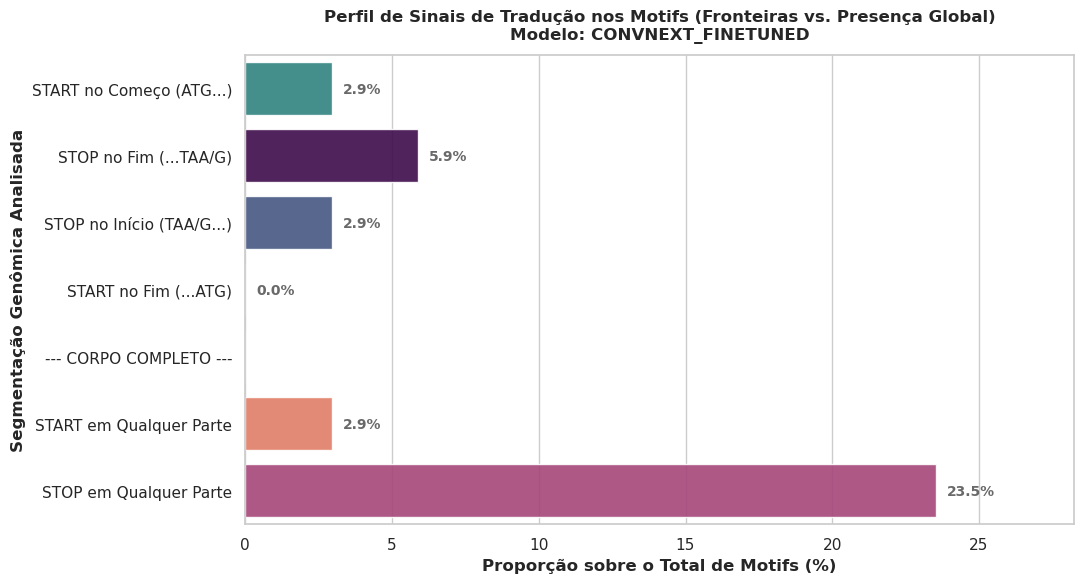

carregando dados para convnext_from_scratch
ConvNext from scratch: 30 validated motifs of 54 total motifs.


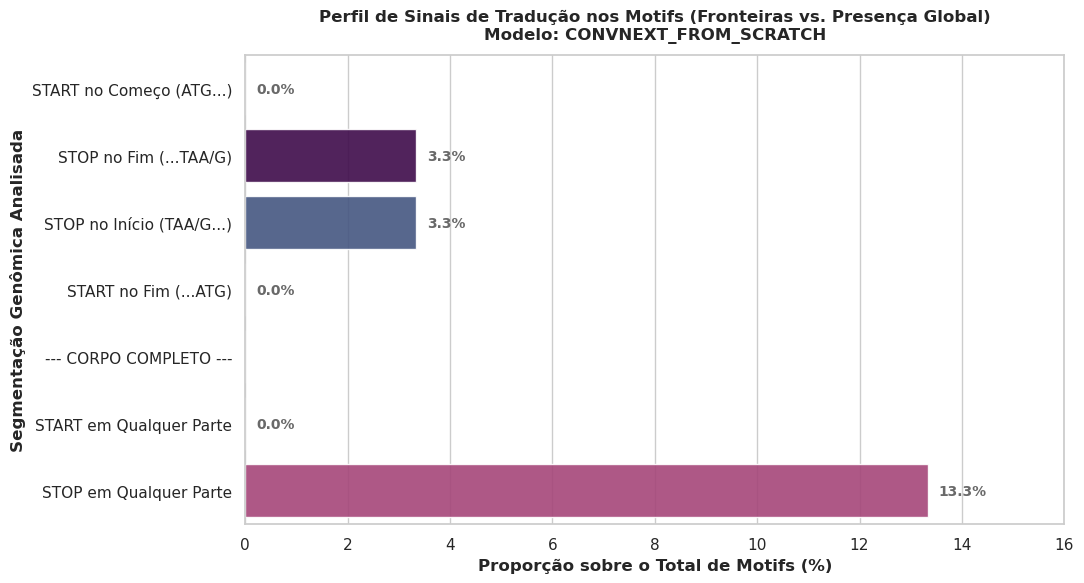

carregando dados para convnext_transfer_from_genus
ConvNext transfer from genus: 40 validated motifs of 61 total motifs.


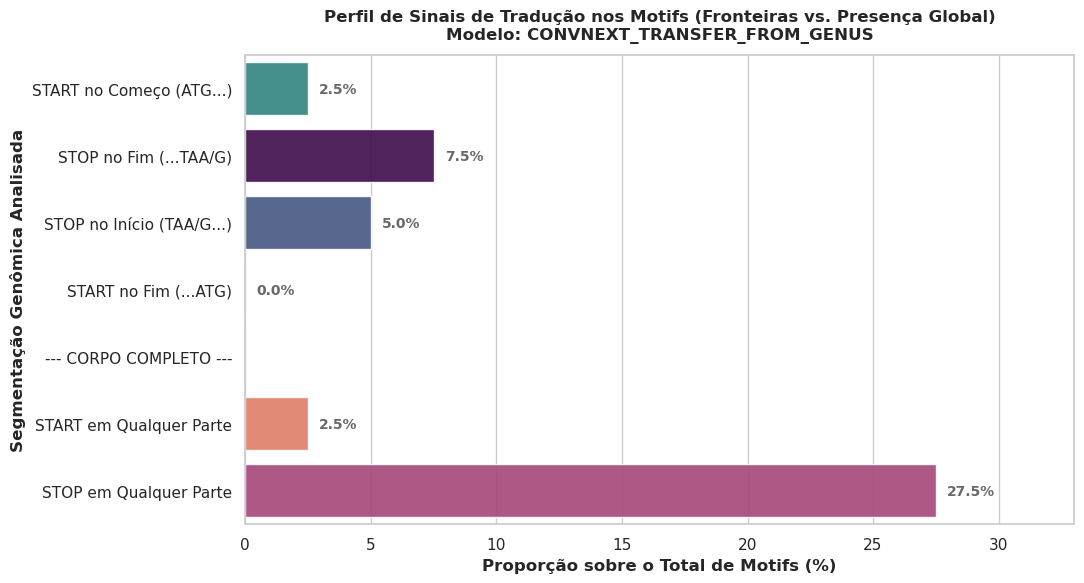

carregando dados para resnet50
ResNet50: 42 validated motifs of 64 total motifs.


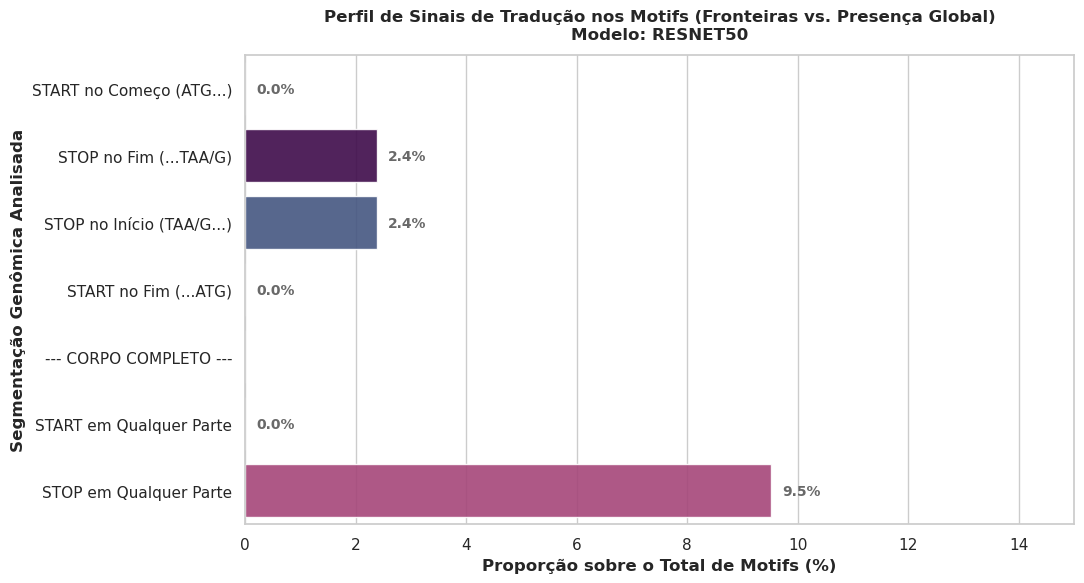

carregando dados para resnet50_finetuned
ResNet50_finetuned: 40 validated motifs of 62 total motifs.


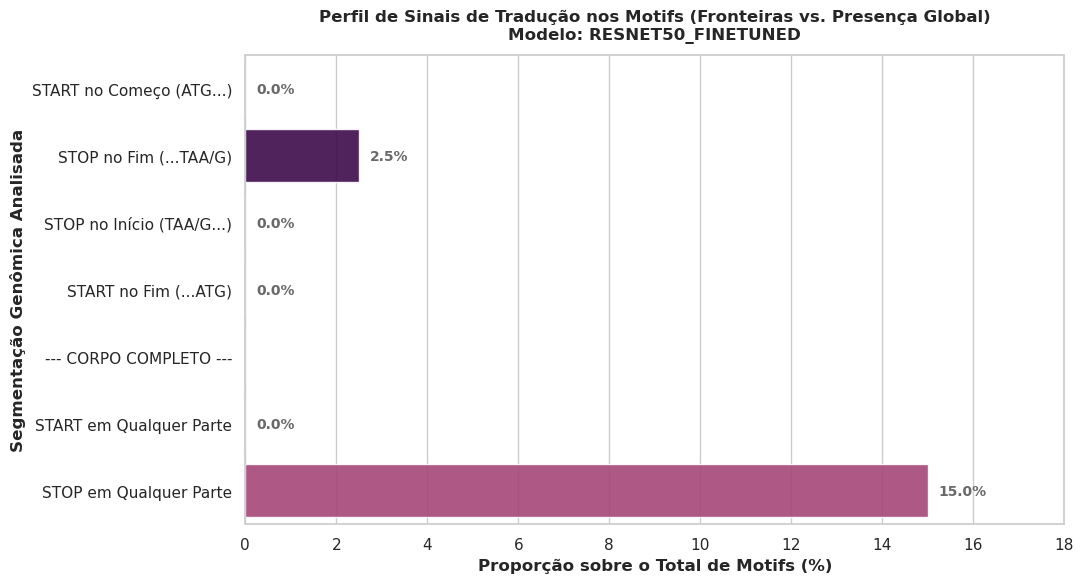

In [34]:
for model in models:
    model_name = model['model_name'].lower().replace(" ","_")
    print(f"carregando dados para {model_name}")
    df_top_motifs = load_validated_motifs(
                        model["model_name"]
                    )
    # 2. Executa a análise estatística (Estratégia C) cruzando os dados com o seu DataFrame de motifs do Pareto
    df_analise = analisar_fronteiras_traducao_single(
        df_top_motifs=df_top_motifs, 
        model_name=model_name,
        rscu_map=rscu_map_loader,
        path_save=f"results_reports/codon_usage_{model_name}_start_stop.png"
    )

In [35]:
for model_dict in models:
    df_jaccard = pd.read_parquet(f'results_motifs/motif_interaction_jaccard_{model_dict['model_name'].lower().replace(" ","_")}.parquet')
    model_dict["jaccard_matrix"] = df_jaccard

In [36]:
models[0]["jaccard_matrix"]

,AAAAACG,AAAATTT,AAATTCT,AACCGTT,ACTAGTA,AGCTGCT,ATGATCA,CCCCAAA,CCCCCCC,CCCCCGG,...,GGGGCCC,GGGGGGA,GGGGGGG,TAAATTA,TACTAGT,TATTTTA,TCCCCCC,TCCCCGG,TGCAGCA,TTTAAGG
AAAAACG,1.000000,0.023609,0.015700,0.011805,0.006883,0.009178,0.012226,0.012560,0.004501,0.004471,...,0.005565,0.006228,0.005441,0.020190,0.007091,0.021145,0.004282,0.006166,0.011344,0.011711
AAAATTT,0.023609,1.000000,0.040129,0.012946,0.011534,0.014822,0.020083,0.015122,0.005633,0.003719,...,0.004209,0.007130,0.005537,0.048248,0.012018,0.051654,0.006830,0.003886,0.015514,0.021760
AAATTCT,0.015700,0.040129,1.000000,0.011902,0.010752,0.014642,0.018323,0.015827,0.005365,0.003188,...,0.005261,0.007877,0.005735,0.033989,0.011086,0.035328,0.007574,0.004627,0.016204,0.017297
AACCGTT,0.011805,0.012946,0.011902,1.000000,0.006139,0.008319,0.009488,0.009768,0.004751,0.006273,...,0.003680,0.005067,0.005057,0.011529,0.005980,0.012757,0.005562,0.005328,0.009539,0.009524
ACTAGTA,0.006883,0.011534,0.010752,0.006139,1.000000,0.007192,0.007498,0.007887,0.003777,0.002529,...,0.003242,0.004337,0.004743,0.013451,0.177596,0.013877,0.004307,0.002074,0.007756,0.007579
AGCTGCT,0.009178,0.014822,0.014642,0.008319,0.007192,1.000000,0.013430,0.010273,0.006805,0.008604,...,0.007147,0.007886,0.007757,0.011772,0.006345,0.011578,0.008785,0.009977,0.021560,0.012363
ATGATCA,0.012226,0.020083,0.018323,0.009488,0.007498,0.013430,1.000000,0.009646,0.004821,0.004964,...,0.003831,0.006528,0.004417,0.019475,0.006939,0.015957,0.005738,0.006385,0.015421,0.011757
CCCCAAA,0.012560,0.015122,0.015827,0.009768,0.007887,0.010273,0.009646,1.000000,0.024807,0.010840,...,0.014661,0.010243,0.014603,0.009364,0.006872,0.010636,0.024209,0.008753,0.010874,0.010103
CCCCCCC,0.004501,0.005633,0.005365,0.004751,0.003777,0.006805,0.004821,0.024807,1.000000,0.060383,...,0.039078,0.039022,0.079014,0.003767,0.004774,0.004655,0.202396,0.012105,0.005794,0.005207
CCCCCGG,0.004471,0.003719,0.003188,0.006273,0.002529,0.008604,0.004964,0.010840,0.060383,1.000000,...,0.029761,0.021300,0.027127,0.002223,0.002798,0.003034,0.056446,0.017163,0.007480,0.004595


In [37]:
def plot_sinergia_codons_rede(df_jaccard, rscu_map, model_name, path_save, top_k_edges=200):
    """
    Extrai as top conexões do grafo de Jaccard e verifica se a co-ocorrência
    está atrelada a uma assinatura pareada de Codon Usage.
    """
    plt.clf()
    plt.close('all')
    
    # 1. Transformar a Matriz de Jaccard em uma lista de Arestas (Pairs)
    # Pegamos apenas o triângulo superior para evitar duplicatas (A-B e B-A)
    df_triu = df_jaccard.where(np.triu(np.ones(df_jaccard.shape), k=1).astype(bool))
    
    # 🛠️ CORREÇÃO: Força nomes diferentes para os eixos antes do reset_index
    # Isso evita o erro "cannot insert motif, already exists"
    df_triu.index.name = 'Motif_A'
    df_triu.columns.name = 'Motif_B'
    
    # Agora empilha e reseta o index de forma segura, já nomeando a coluna de valores como 'Jaccard'
    df_edges = df_triu.stack().reset_index(name='Jaccard')
    
    # Ordena para pegar apenas as correlações mais fortes da rede
    df_top_edges = df_edges.sort_values(by='Jaccard', ascending=False).head(top_k_edges).copy()
    
    if len(df_top_edges) == 0:
        print(f"⚠️ Sem arestas válidas para o modelo {model_name}.")
        return pd.DataFrame()
        
    # 2. Mapeamento Biológico (RSCU Médio de cada Motivo na Aresta)
    df_top_edges['RSCU_A'] = df_top_edges['Motif_A'].apply(lambda x: calcular_rscu_medio_motivo(x, rscu_map))
    df_top_edges['RSCU_B'] = df_top_edges['Motif_B'].apply(lambda x: calcular_rscu_medio_motivo(x, rscu_map))
    
    # Limpa possíveis NaNs (motivos puramente de padding)
    df_top_edges = df_top_edges.dropna(subset=['RSCU_A', 'RSCU_B'])
    
    # 3. Estatística de Pareamento
    p_corr, p_val = pearsonr(df_top_edges['RSCU_A'], df_top_edges['RSCU_B'])
    
    # 4. Visualização 2D (Sinergia de Códons)
    fig, ax = plt.subplots(figsize=(8, 8))
    sns.set_theme(style="whitegrid")
    
    # Plot de Densidade e Dispersão
    sns.kdeplot(data=df_top_edges, x='RSCU_A', y='RSCU_B', cmap="Reds", fill=True, alpha=0.6, ax=ax)
    sns.scatterplot(data=df_top_edges, x='RSCU_A', y='RSCU_B', 
                    hue='Jaccard', palette='viridis', size='Jaccard', sizes=(40, 150), ax=ax, edgecolor='black', alpha=0.8)
    
    # Linhas de Neutralidade (RSCU = 1.0)
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.7)
    ax.axvline(1.0, color='gray', linestyle='--', alpha=0.7)
    
    # Anotações dos Quadrantes Biológicos
    #ax.text(1.05, 1.05, 'Sinergia de\nCódons Otimizados', color='darkred', fontsize=10, alpha=0.7)
    #ax.text(0.70, 0.70, 'Clusters de\nCódons Raros\n(Traffic Jams)', color='darkblue', fontsize=10, alpha=0.7)
    
    # Caixa de estatística
    texto_stats = f"Top {top_k_edges} Arestas\nPearson r: {p_corr:.3f} (p: {p_val:.2e})"
    ax.text(0.05, 0.95, texto_stats, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9))
            
    ax.set_title(f'Sinergia de Codon Usage nas Co-ocorrências (Jaccard)\nModelo: {model_name.upper()}', fontweight='bold', fontsize=13, pad=15)
    ax.set_xlabel('RSCU Médio do Motivo A', fontweight='bold')
    ax.set_ylabel('RSCU Médio do Motivo B', fontweight='bold')
    ax.legend(title='Força (Jaccard)', loc='lower right')
    
    plt.tight_layout()
    os.makedirs(os.path.dirname(path_save), exist_ok=True)
    
    # Salva garantindo a criação limpa do nome do arquivo (adicionei .png no path caso falte)
    path_full = path_save if path_save.endswith('.png') else f"{path_save}_{model_name}.png"
    plt.savefig(path_full, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close('all')
    
    print(f"🧬 [{model_name}] Plot de Sinergia de Códons gerado! (Pearson Pareamento: {p_corr:.3f})")
    
    return df_top_edges

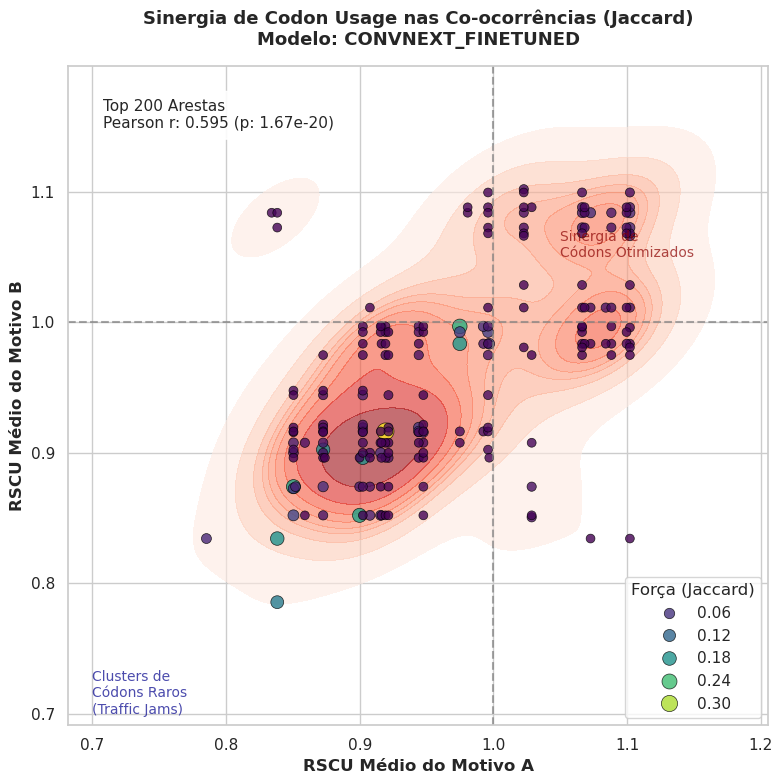

🧬 [convnext_finetuned] Plot de Sinergia de Códons gerado! (Pearson Pareamento: 0.595)


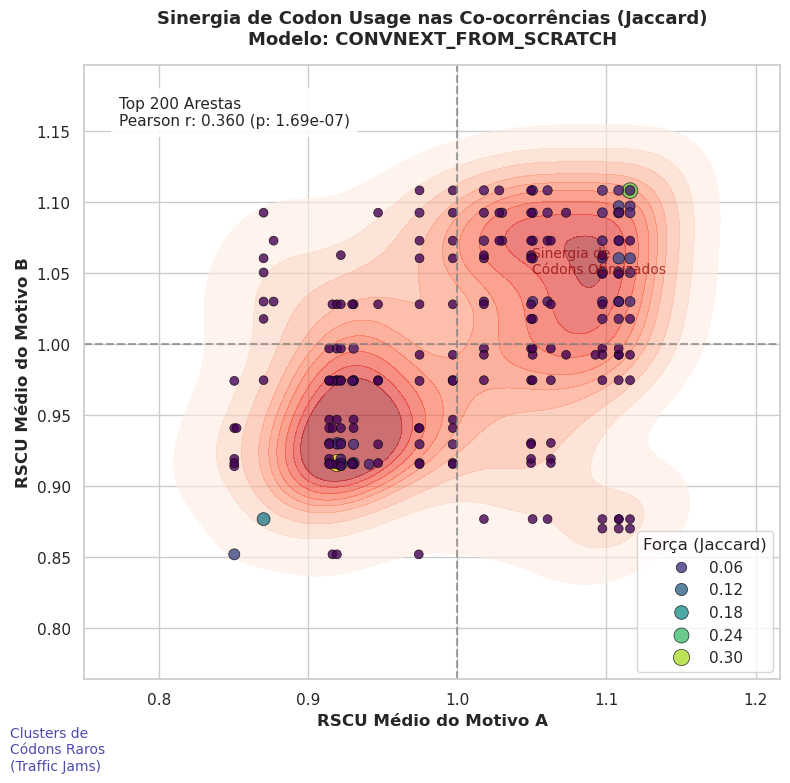

🧬 [convnext_from_scratch] Plot de Sinergia de Códons gerado! (Pearson Pareamento: 0.360)


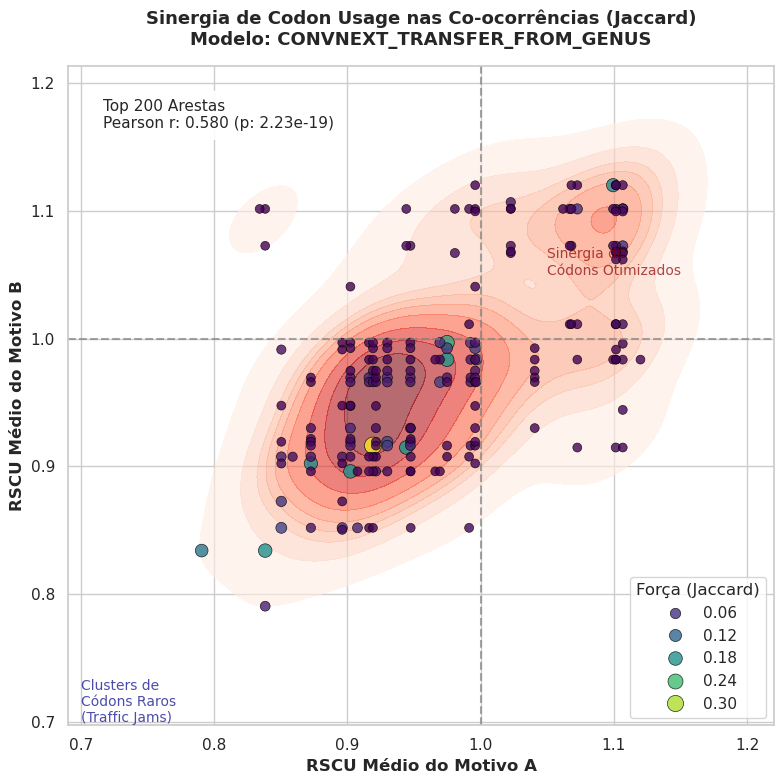

🧬 [convnext_transfer_from_genus] Plot de Sinergia de Códons gerado! (Pearson Pareamento: 0.580)


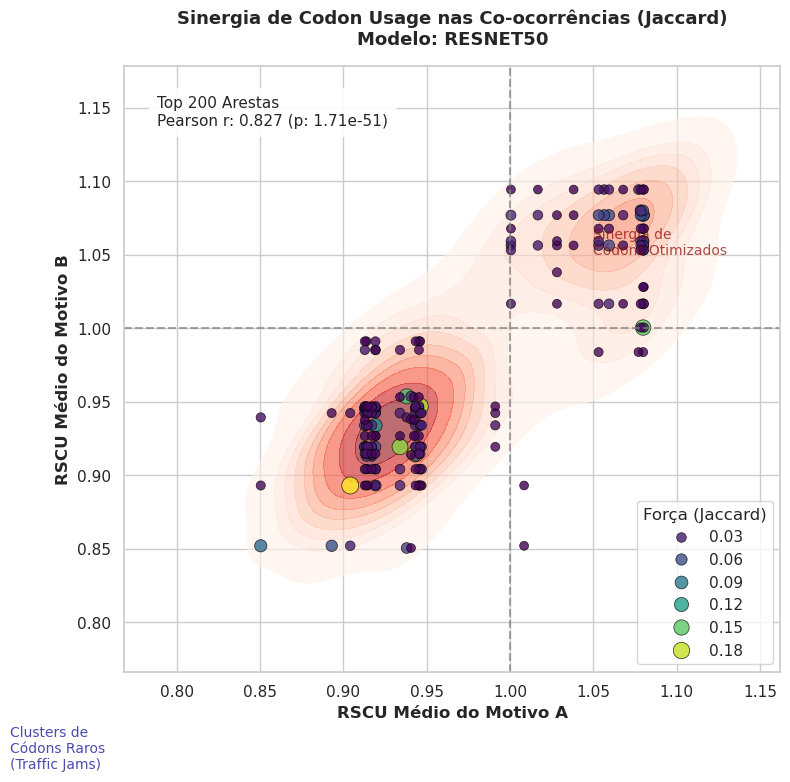

🧬 [resnet50] Plot de Sinergia de Códons gerado! (Pearson Pareamento: 0.827)


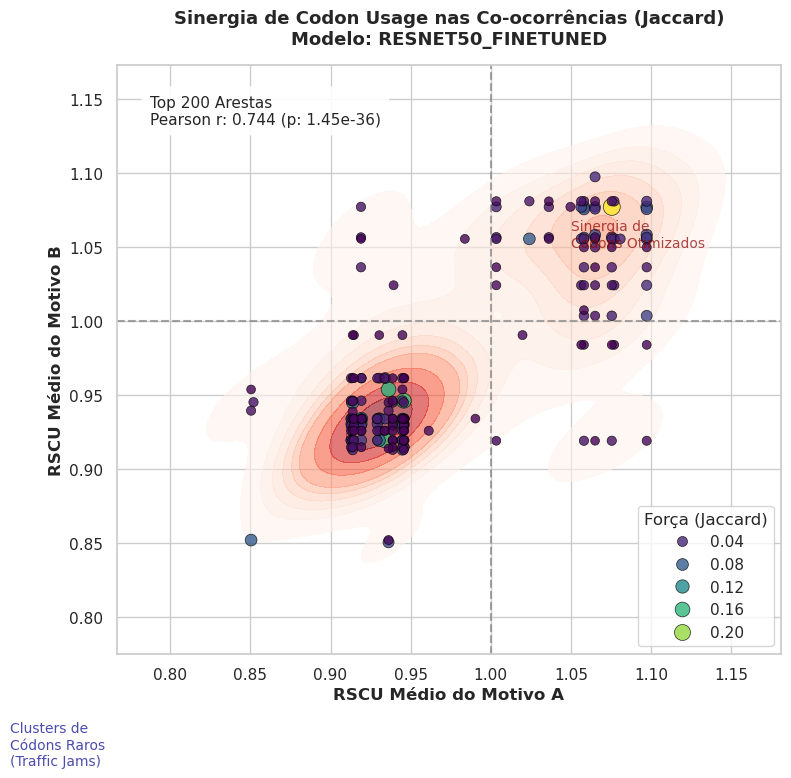

🧬 [resnet50_finetuned] Plot de Sinergia de Códons gerado! (Pearson Pareamento: 0.744)


In [38]:
for model_dict in models:
    model_name = model_dict['model_name'].lower().replace(" ","_")
    plot_sinergia_codons_rede(model_dict["jaccard_matrix"], rscu_map_loader, model_name, f"./results_plots/plot_codon_cluster", top_k_edges=200)

ConvNext finetuned: 34 validated motifs of 63 total motifs.
ConvNext from scratch: 30 validated motifs of 54 total motifs.
ConvNext transfer from genus: 40 validated motifs of 61 total motifs.
ResNet50: 42 validated motifs of 64 total motifs.
ResNet50_finetuned: 40 validated motifs of 62 total motifs.


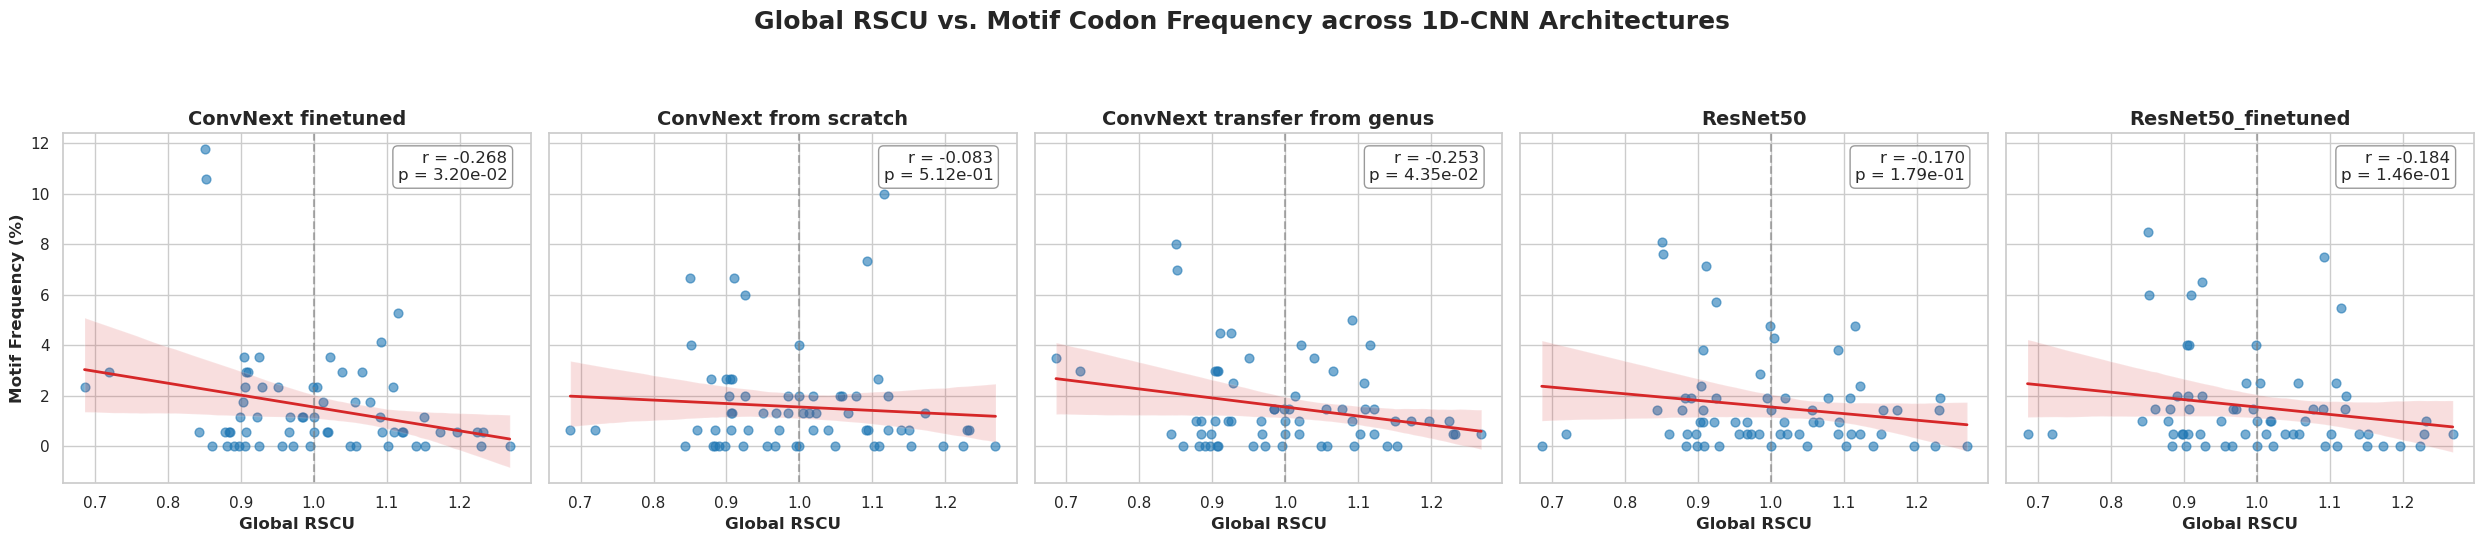

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import os

# Figure creation with 1 row and 5 columns
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharey=True)
fig.suptitle('Global RSCU vs. Motif Codon Frequency across 1D-CNN Architectures', fontsize=18, fontweight='bold', y=1.08)

for ax, model_dict in zip(axes, models):
    # File name formatting based on the original logic
    model_name = model_dict['model_name'].lower().replace(" ", "_")
    display_name = model_dict['model_name']
    
    # Load motif data saved on disk
    df_top_motifs = load_validated_motifs(
                        model_dict["model_name"]
                    )
    
    # Codon counting logic extracted from the plot_codon_signature_match function
    codon_counts = {codon: 0 for codon in rscu_map_loader.keys()}
    col_motif = 'motif' if 'motif' in df_top_motifs.columns else 'kmer'
    
    for row in df_top_motifs.itertuples():
        m = str(getattr(row, col_motif)).upper().strip()
        if len(m) >= 3 and not any(char in m for char in ['N', 'X', '-', '_']):
            for i in range(len(m) - 2):
                codon = m[i:i+3]
                if codon in codon_counts:
                    codon_counts[codon] += 1
                    
    total_codons = sum(codon_counts.values())
    x_vals, y_vals = [], []
    
    if total_codons > 0:
        for codon, count in codon_counts.items():
            x_vals.append(rscu_map_loader[codon])
            y_vals.append((count / total_codons) * 100)
            
    # Scatter plot with Linear Regression
    sns.regplot(
        x=x_vals, y=y_vals, ax=ax, 
        scatter_kws={'alpha': 0.6, 'color': '#1f77b4', 's': 40}, 
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    
    # Add RSCU neutrality line
    ax.axvline(x=1.0, color='gray', linestyle='--', alpha=0.6)
    
    # Calculate and annotate Pearson correlation
    if len(x_vals) > 1:
        r, p = pearsonr(x_vals, y_vals)
        ax.text(0.95, 0.95, f'r = {r:.3f}\np = {p:.2e}', transform=ax.transAxes, 
                ha='right', va='top', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))
    
    # Subplot aesthetics
    ax.set_title(display_name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Global RSCU', fontweight='bold')
    
    if ax == axes[0]:
        ax.set_ylabel('Motif Frequency (%)', fontweight='bold')

plt.tight_layout()
os.makedirs("results_reports", exist_ok=True)
plt.savefig('results_reports/panel_a_rscu_vs_frequency.png', dpi=300, bbox_inches='tight')
plt.show()

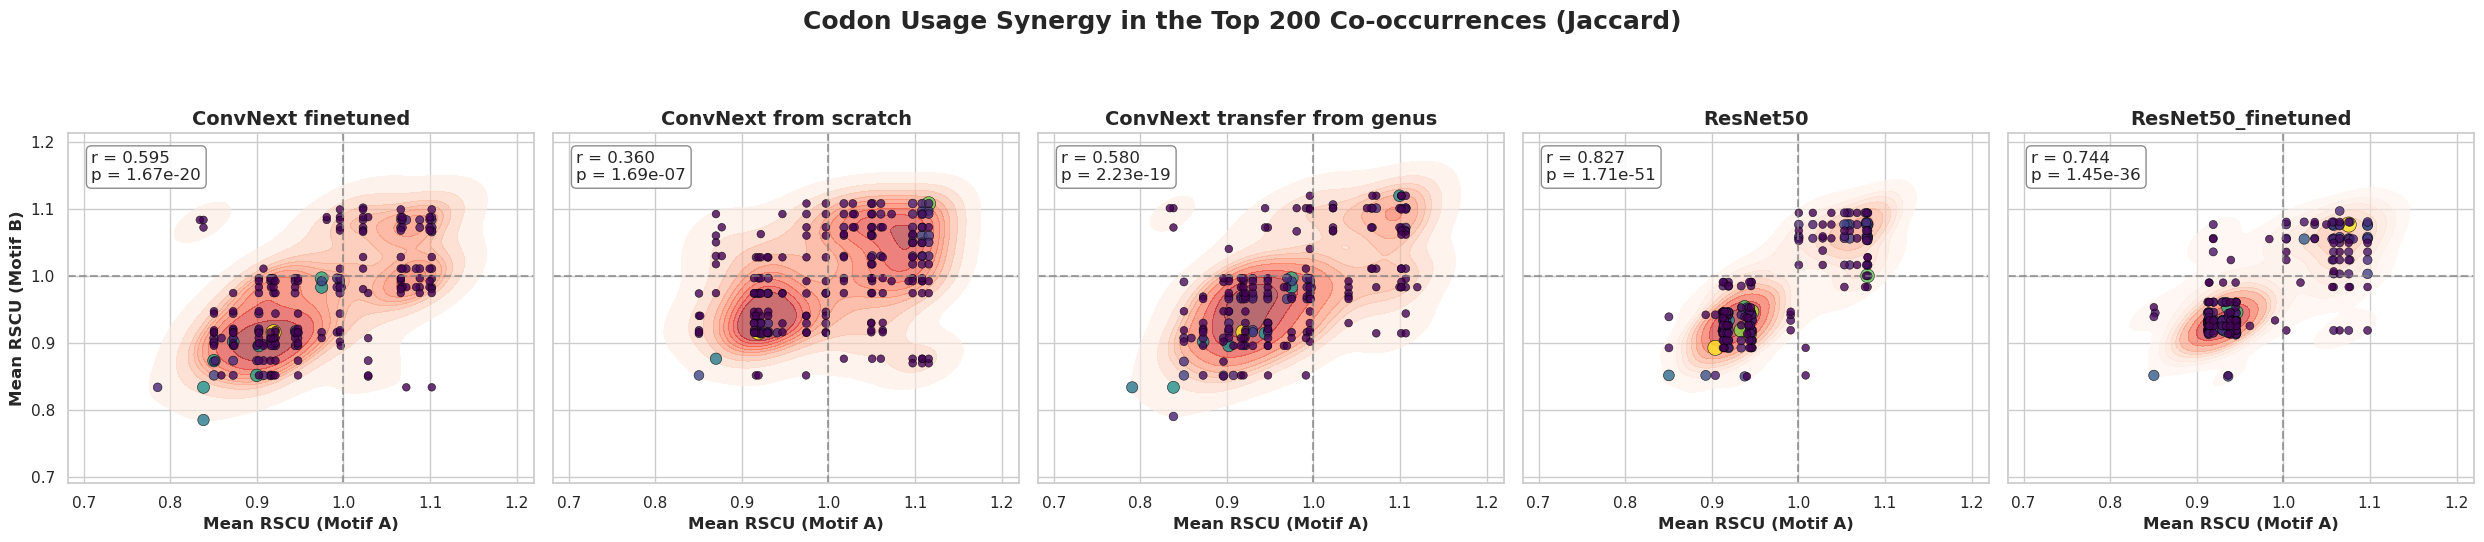

In [41]:
# Figure creation with 1 row and 5 columns
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=True, sharey=True)
fig.suptitle('Codon Usage Synergy in the Top 200 Co-occurrences (Jaccard)', fontsize=18, fontweight='bold', y=1.08)

for ax, model_dict in zip(axes, models):
    display_name = model_dict['model_name']
    
    # Load the previously processed Jaccard matrix into memory
    df_jaccard = model_dict['jaccard_matrix']
    
    # Extract the upper triangle to avoid duplicate pairs
    df_triu = df_jaccard.where(np.triu(np.ones(df_jaccard.shape), k=1).astype(bool))
    df_triu.index.name = 'Motif_A'
    df_triu.columns.name = 'Motif_B'
    
    # Stack and get the Top 200 edges
    df_edges = df_triu.stack().reset_index(name='Jaccard')
    df_top = df_edges.sort_values(by='Jaccard', ascending=False).head(200).copy()
    
    # Apply mapped RSCU
    df_top['RSCU_A'] = df_top['Motif_A'].apply(lambda x: calcular_rscu_medio_motivo(x, rscu_map_loader))
    df_top['RSCU_B'] = df_top['Motif_B'].apply(lambda x: calcular_rscu_medio_motivo(x, rscu_map_loader))
    df_top = df_top.dropna(subset=['RSCU_A', 'RSCU_B'])
    
    # Density and Scatter plot on the same axis
    sns.kdeplot(data=df_top, x='RSCU_A', y='RSCU_B', cmap="Reds", fill=True, alpha=0.6, ax=ax)
    sns.scatterplot(
        data=df_top, x='RSCU_A', y='RSCU_B', hue='Jaccard', palette='viridis', 
        size='Jaccard', sizes=(30, 120), ax=ax, edgecolor='black', alpha=0.8, legend=False
    )
    
    # Neutrality Lines (RSCU = 1.0)
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.7)
    ax.axvline(1.0, color='gray', linestyle='--', alpha=0.7)
    
    # Calculate and annotate Pearson correlation
    if len(df_top) > 1:
        r, p = pearsonr(df_top['RSCU_A'], df_top['RSCU_B'])
        ax.text(0.05, 0.95, f'r = {r:.3f}\np = {p:.2e}', transform=ax.transAxes, 
                ha='left', va='top', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))
        
    # Subplot aesthetics
    ax.set_title(display_name, fontsize=14, fontweight='bold')
    ax.set_xlabel('Mean RSCU (Motif A)', fontweight='bold')
    
    if ax == axes[0]:
        ax.set_ylabel('Mean RSCU (Motif B)', fontweight='bold')

plt.tight_layout()
plt.savefig('results_reports/panel_b_codon_synergy.png', dpi=300, bbox_inches='tight')
plt.show()